# [핸즈온 머신러닝] Chapter 7 – 차원 축소 (Dimensionality Reduction)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/jsmak/handson-mlp-study/blob/main/ch07/07_dimensionality_reduction_kr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>
<br clear="left"/>

> **📚 출처 및 라이선스**
>
> - **원본 노트북**: [rickiepark/handson-mlp](https://github.com/rickiepark/handson-mlp) – [`07_dimensionality_reduction.ipynb`](https://github.com/rickiepark/handson-mlp/blob/main/07_dimensionality_reduction.ipynb) (박해선 님, 『핸즈온 머신러닝 with 사이킷런, 파이토치』 한빛미디어, 2026 예제 코드)
> - **원저작**: [ageron/handson-mlp](https://github.com/ageron/handson-mlp) (Aurélien Géron, *Hands-On Machine Learning with Scikit-Learn and PyTorch*, O'Reilly)
> - **라이선스**: 원본 코드는 [Apache License 2.0](https://github.com/rickiepark/handson-mlp/blob/main/LICENSE)을 따릅니다.
> - **변경 사항**: 개인 학습(인프런 챌린지 복습) 목적으로 원본 노트북을 바탕으로 한국어 설명·주석을 추가하고, 셀 구성을 책의 절 번호에 맞춰 재정리했습니다. 책 본문은 포함하지 않습니다.

특성이 너무 많을 때 생기는 **차원의 저주**와 이를 줄이는 두 접근법(투영, 매니폴드 학습)을 살펴보고, **PCA**, **랜덤 투영**, **LLE** 등 대표적인 차원 축소 기법을 3D 데이터셋, 스위스 롤, MNIST로 실습합니다.

| 절 | 내용 | 주요 코드 |
|---|---|---|
| 7.1 | 차원의 저주 | – |
| 7.2 | 차원 축소 접근법 (투영, 매니폴드 학습) | `make_swiss_roll` |
| 7.3 | 주성분 분석 (PCA, 랜덤 PCA, 점진적 PCA) | `PCA`, `IncrementalPCA`, `np.memmap` |
| 7.4 | 랜덤 투영 | `GaussianRandomProjection`, `SparseRandomProjection` |
| 7.5 | 지역 선형 임베딩 (LLE) | `LocallyLinearEmbedding` |
| 7.6 | 다른 차원 축소 기법 | `MDS`, `Isomap`, `TSNE` |

⚠ 7.4절은 2.5GB 정도의 메모리를 사용하고, 유사역행렬 계산 셀은 몇 분 걸릴 수 있습니다. `my_mnist.mmap`(약 188MB) 파일이 현재 폴더에 만들어집니다.

## **7.1 차원의 저주**

고차원 공간에서는 대부분의 점이 경계 가까이에 있고, 임의의 두 점 사이 거리가 매우 멀어 데이터셋이 **희소**해집니다. 그래서 새 샘플도 훈련 샘플과 멀리 떨어질 가능성이 높아 예측이 불안정해지고 과대적합 위험이 커집니다. (이 절은 코드 예제가 없습니다.)

## **7.2 차원 축소 접근법**

### **7.2.1 투영**

실전 데이터는 모든 차원에 균일하게 퍼져 있지 않고 고차원 공간 안의 **저차원 부분 공간(subspace)** 근처에 놓여 있는 경우가 많습니다. 먼저 회전된 타원 모양의 작은 3D 데이터셋을 만듭니다.

점이 고르지 않게 분포하고 잡음이 꽤 많은 3D 데이터셋 60개를 생성합니다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))  # 3D 데이터셋 초기화
rng = np.random.default_rng(seed=42)
angles = (rng.random(m) ** 3 + 0.5) * 2 * np.pi  # 고르지 않은 분포
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # 타원
X += 0.28 * rng.standard_normal((m, 3))  # 잡음 추가
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)  # 3D 회전
X += [0.2, 0, 0.2]  # 약간 이동

PCA로 찾은 투영 평면과 각 샘플을 평면에 수직으로 투영한 모습을 3D로 그립니다(그림 7-2).

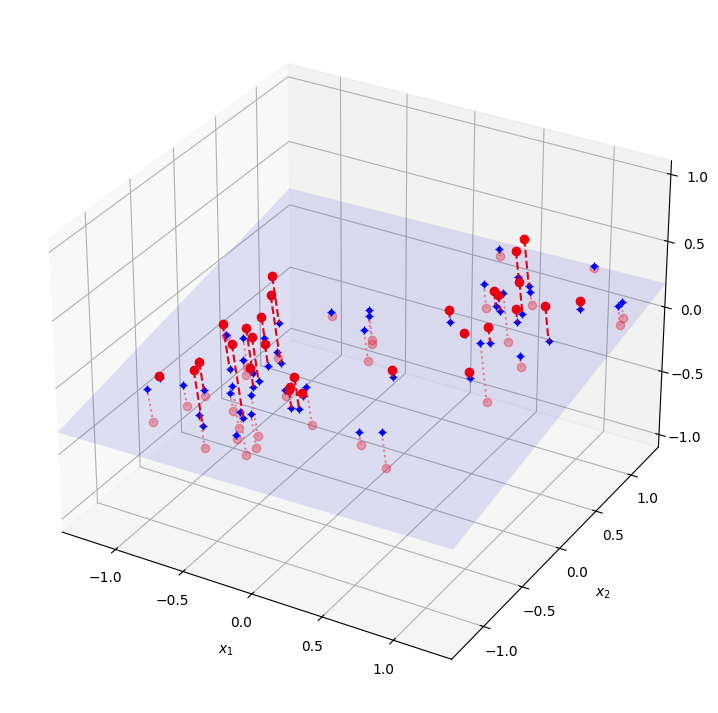

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)  # 2D로 축소한 데이터셋
X3D_inv = pca.inverse_transform(X2D)  # 투영된 샘플의 3D 위치
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered)

axes = [-1.4, 1.4, -1.4, 1.4, -1.1, 1.1]
x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 10),
                     np.linspace(axes[2], axes[3], 10))
w1, w2 = np.linalg.solve(Vt[:2, :2], Vt[:2, 2])  # 투영 평면의 계수
z = w1 * (x1 - pca.mean_[0]) + w2 * (x2 - pca.mean_[1]) - pca.mean_[2]  # 평면
X3D_above = X[X[:, 2] >= X3D_inv[:, 2]]  # 평면 위쪽 샘플
X3D_below = X[X[:, 2] < X3D_inv[:, 2]]  # 평면 아래쪽 샘플

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

# 평면 아래쪽 샘플과 투영선을 먼저 그림
ax.plot(X3D_below[:, 0], X3D_below[:, 1], X3D_below[:, 2], "ro", alpha=0.3)
for i in range(m):
    if X[i, 2] < X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], ":", color="#F88")

ax.plot_surface(x1, x2, z, alpha=0.1, color="b")  # 투영 평면
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b+")  # 투영된 샘플
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b.")

# 평면 위쪽 투영선과 샘플을 그림
for i in range(m):
    if X[i, 2] >= X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], "r--")

ax.plot(X3D_above[:, 0], X3D_above[:, 1], X3D_above[:, 2], "ro")


def set_xyz_axes(ax, axes):
    # 3D 그래프의 축 이름과 범위를 설정하는 함수
    ax.xaxis.set_rotate_label(False)
    ax.yaxis.set_rotate_label(False)
    ax.zaxis.set_rotate_label(False)
    ax.set_xlabel("$x_1$", labelpad=8, rotation=0)
    ax.set_ylabel("$x_2$", labelpad=8, rotation=0)
    ax.set_zlabel("$x_3$", labelpad=8, rotation=0)
    ax.set_xlim(axes[0:2])
    ax.set_ylim(axes[2:4])
    ax.set_zlim(axes[4:6])


set_xyz_axes(ax, axes)
ax.set_zticks([-1, -0.5, 0, 0.5, 1])
plt.show()

→ 샘플이 거의 평면 형태로 놓여 있습니다. 고차원(3D) 공간 안의 저차원(2D) 부분 공간입니다.

평면에 투영한 결과를 새 좌표축 $z_1$, $z_2$로 그립니다(그림 7-3).

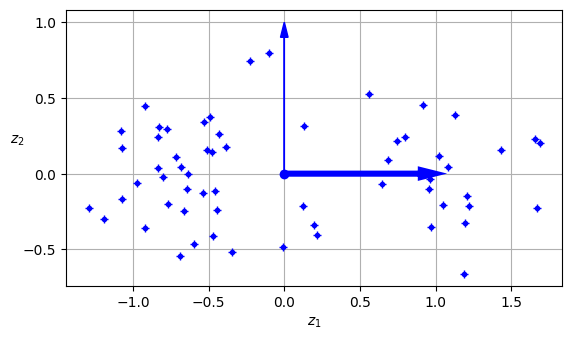

In [3]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, aspect="equal")
ax.plot(X2D[:, 0], X2D[:, 1], "b+")
ax.plot(X2D[:, 0], X2D[:, 1], "b.")
ax.plot([0], [0], "bo")
ax.arrow(0, 0, 1, 0, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc="b", ec="b", linewidth=4)
ax.arrow(0, 0, 0, 1, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc="b", ec="b", linewidth=1)
ax.set_xlabel("$z_1$")
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_ylabel("$z_2$", rotation=0)
ax.set_axisbelow(True)
ax.grid(True)
plt.show()

→ 3D 데이터셋을 2D로 줄였습니다. 두 축은 평면에 투영된 좌표인 새 특성 $z_1$, $z_2$입니다.

### **7.2.2 매니폴드 학습**

부분 공간이 뒤틀리거나 휘어 있으면 투영이 최선이 아닙니다. 대표적인 예가 **스위스 롤(swiss roll)** 데이터셋입니다.

스위스 롤 1,000개를 만들고 3D로 그립니다(그림 7-4). 색은 롤을 따라 감긴 위치 `t`입니다.

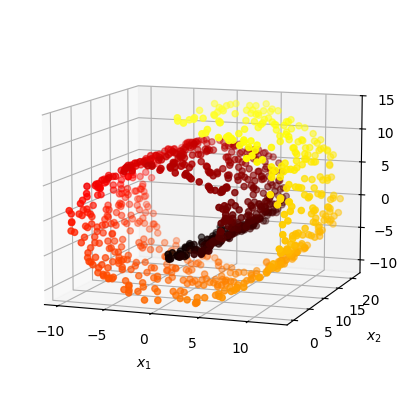

In [4]:
from sklearn.datasets import make_swiss_roll
from matplotlib.colors import ListedColormap

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))  # 조금 어두운 hot 컬러맵

axes = [-11.5, 14, -2, 23, -12, 15]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t, cmap=darker_hot)
ax.view_init(10, -70)
set_xyz_axes(ax, axes)
plt.show()

$x_3$를 버리고 평면에 투영한 경우(왼쪽)와 롤을 펼친 경우(오른쪽)를 비교합니다(그림 7-5).

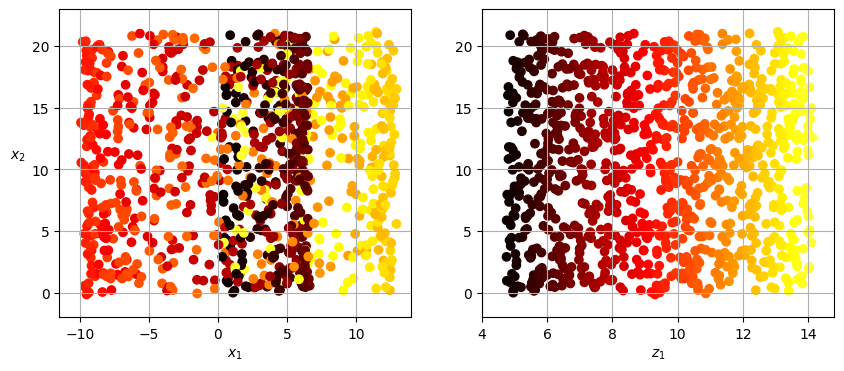

In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(121)  # 평면에 투영 (x3를 버림)
plt.scatter(X_swiss[:, 0], X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis(axes[:4])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", labelpad=10, rotation=0)
plt.grid(True)

plt.subplot(122)  # 스위스 롤을 펼침
plt.scatter(t, X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis([4, 14.8, axes[2], axes[3]])
plt.xlabel("$z_1$")
plt.grid(True)

plt.show()

→ 투영하면 롤의 층이 서로 뭉개지지만(왼쪽), 펼치면 깔끔한 2D 데이터셋이 됩니다(오른쪽).

**매니폴드 가정**에는 "저차원 매니폴드에서 작업이 더 간단해진다"는 암묵적 가정이 따라오기도 하지만 항상 맞지는 않습니다. 두 가지 결정 경계로 비교합니다(그림 7-6).

- 첫 번째 행: $2(t-4) > x_2$ 로 클래스를 나눔 → 3D에서는 복잡, 펼친 2D에서는 직선
- 두 번째 행: $x_1 > 5$ 로 클래스를 나눔 → 3D에서는 수직 평면, 펼친 2D에서는 네 개의 선분

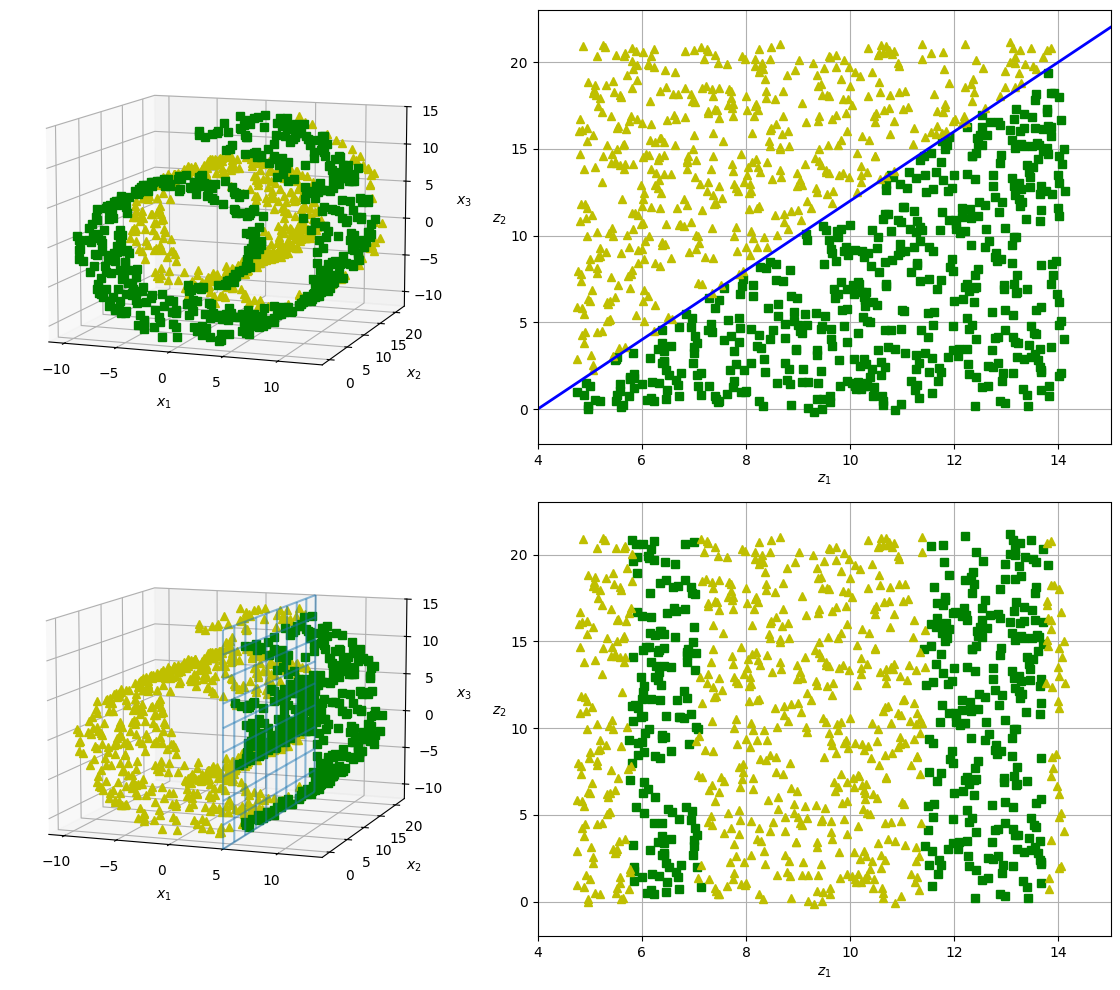

In [6]:
x2s = np.linspace(axes[2], axes[3], 10)
x3s = np.linspace(axes[4], axes[5], 10)
x2, x3 = np.meshgrid(x2s, x3s)

fig = plt.figure(figsize=(12, 10))

# --- 첫 번째 행: 2(t - 4) > x2 → 펼친 매니폴드에서 결정 경계가 직선 ---
positive_class = 2 * (t - 4) > X_swiss[:, 1]
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

ax1 = fig.add_subplot(2, 2, 1, projection="3d")
ax1.view_init(10, -70)
ax1.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax1.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
set_xyz_axes(ax1, axes)

ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax2.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax2.plot([4, 15], [0, 22], "b-", linewidth=2)  # 결정 경계 x2 = 2(t - 4)
ax2.axis([4, 15, axes[2], axes[3]])
ax2.set_xlabel("$z_1$")
ax2.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax2.grid(True)

# --- 두 번째 행: x1 > 5 → 3D에서는 수직 평면, 펼치면 복잡 ---
positive_class = X_swiss[:, 0] > 5
X_pos = X_swiss[positive_class]
X_neg = X_swiss[~positive_class]

ax3 = fig.add_subplot(2, 2, 3, projection="3d")
ax3.view_init(10, -70)
ax3.plot(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], "y^")
ax3.plot_wireframe(5, x2, x3, alpha=0.5)  # 결정 경계 x1 = 5 평면
ax3.plot(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], "gs")
set_xyz_axes(ax3, axes)

ax4 = fig.add_subplot(2, 2, 4)
ax4.plot(t[positive_class], X_swiss[positive_class, 1], "gs")
ax4.plot(t[~positive_class], X_swiss[~positive_class, 1], "y^")
ax4.axis([4, 15, axes[2], axes[3]])
ax4.set_xlabel("$z_1$")
ax4.set_ylabel("$z_2$", rotation=0, labelpad=8)
ax4.grid(True)

plt.tight_layout()
plt.show()

→ 위쪽은 펼치면 단순해지는 경우, 아래쪽은 오히려 3D에서 더 단순한 경우입니다. 차원 축소가 항상 더 간단한 솔루션을 주지는 않으며 데이터셋에 달려 있습니다.

## **7.3 주성분 분석**

**주성분 분석(PCA, principal component analysis)** 은 데이터에 가장 가까운 초평면을 찾아 데이터를 그 평면에 투영합니다.

### **7.3.1 분산 보존**

분산을 가장 많이 보존하는 축을 고르면 원본과 투영 결과 사이의 평균 제곱 거리가 최소가 되어 정보 손실이 가장 적습니다.

2D 데이터셋을 세 개의 축(실선·파선·점선)에 각각 투영해 보존되는 분산을 비교합니다(그림 7-7).

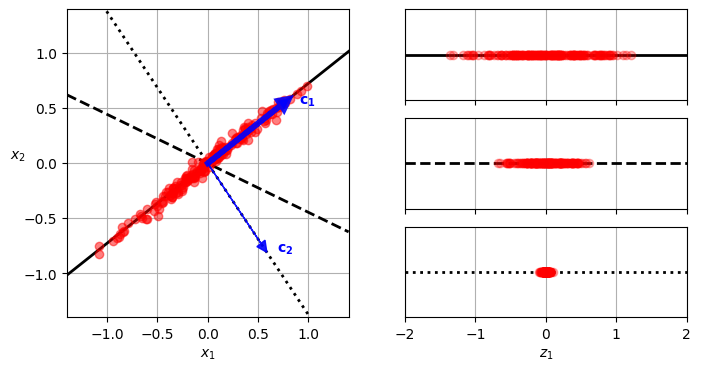

In [7]:
angle = np.pi / 5
stretch = 5
m = 200

rng = np.random.default_rng(seed=3)
X_line = rng.standard_normal((m, 2)) / 10
X_line = X_line @ np.array([[stretch, 0], [0, 1]])  # 늘이기
X_line = X_line @ [[np.cos(angle), np.sin(angle)],
                   [np.sin(angle), np.cos(angle)]]  # 회전

u1 = np.array([np.cos(angle), np.sin(angle)])  # 실선 방향
u2 = np.array([np.cos(angle - 2 * np.pi / 6), np.sin(angle - 2 * np.pi / 6)])  # 파선 방향
u3 = np.array([np.cos(angle - np.pi / 2), np.sin(angle - np.pi / 2)])  # 점선 방향

X_proj1 = X_line @ u1.reshape(-1, 1)
X_proj2 = X_line @ u2.reshape(-1, 1)
X_proj3 = X_line @ u3.reshape(-1, 1)

plt.figure(figsize=(8, 4))
plt.subplot2grid((3, 2), (0, 0), rowspan=3)
plt.plot([-1.4, 1.4], [-1.4 * u1[1] / u1[0], 1.4 * u1[1] / u1[0]], "k-", linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u2[1] / u2[0], 1.4 * u2[1] / u2[0]], "k--", linewidth=2)
plt.plot([-1.4, 1.4], [-1.4 * u3[1] / u3[0], 1.4 * u3[1] / u3[0]], "k:", linewidth=2)
plt.plot(X_line[:, 0], X_line[:, 1], "ro", alpha=0.5)
plt.arrow(0, 0, u1[0], u1[1], head_width=0.1, linewidth=4, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.arrow(0, 0, u3[0], u3[1], head_width=0.1, linewidth=1, alpha=0.9,
          length_includes_head=True, head_length=0.1, fc="b", ec="b", zorder=10)
plt.text(u1[0] + 0.1, u1[1] - 0.05, r"$\mathbf{c_1}$", color="blue")
plt.text(u3[0] + 0.1, u3[1], r"$\mathbf{c_2}$", color="blue")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", rotation=0)
plt.axis([-1.4, 1.4, -1.4, 1.4])
plt.grid()

# 오른쪽: 각 축에 투영한 결과 (위부터 실선, 파선, 점선)
for row, (X_proj, style) in enumerate([(X_proj1, "k-"), (X_proj2, "k--"), (X_proj3, "k:")]):
    plt.subplot2grid((3, 2), (row, 1))
    plt.plot([-2, 2], [0, 0], style, linewidth=2)
    plt.plot(X_proj[:, 0], np.zeros(m), "ro", alpha=0.3)
    plt.gca().get_yaxis().set_ticks([])
    if row < 2:
        plt.gca().get_xaxis().set_ticklabels([])
    plt.axis([-2, 2, -1, 1])
    plt.grid()
plt.xlabel("$z_1$")

plt.show()

→ 실선에 투영하면 분산이 가장 크게, 점선에 투영하면 가장 작게, 파선은 중간 정도로 보존됩니다.

### **7.3.2 주성분**

PCA는 분산이 최대인 축(1번째 주성분)을 찾고, 그 축에 직교하면서 남은 분산을 최대로 보존하는 축(2번째 주성분)을 찾는 식으로 차원 수만큼 축을 찾습니다. 주성분은 **특잇값 분해(SVD)** $\mathbf{X} = \mathbf{U}\Sigma\mathbf{V}^\top$의 $\mathbf{V}$ 열에 담겨 있습니다.

앞의 3D 데이터셋을 원점에 맞춘 뒤 `np.linalg.svd()`로 처음 두 주성분 단위 벡터를 구합니다.

In [8]:
X_centered = X - X.mean(axis=0)  # PCA는 데이터가 원점에 맞춰져 있다고 가정
U, s, Vt = np.linalg.svd(X_centered)
c1 = Vt[0]  # 첫 번째 주성분
c2 = Vt[1]  # 두 번째 주성분
print(c1, c2)

[-0.66824153 -0.73208333 -0.13231495] [ 0.74374636 -0.66151587 -0.09611511]


→ `svd()`는 $\mathbf{V}$가 아니라 전치된 $\mathbf{V}^\top$(`Vt`)를 반환하므로 주성분은 `Vt`의 행입니다.

`svd()`는 $\Sigma$ 대신 대각 원소만 담은 벡터 `s`를 반환합니다. `s`로 $\Sigma$를 만들어 $\mathbf{U}\Sigma\mathbf{V}^\top$가 원래 행렬과 같은지 확인합니다.

In [9]:
m, n = X.shape
Σ = np.zeros_like(X_centered)  # m × n 크기의 0 행렬
Σ[:n, :n] = np.diag(s)  # 위쪽 n개 행의 대각에 특잇값을 채움
print(np.allclose(X_centered, U @ Σ @ Vt))

True


→ `True`: 세 행렬의 곱으로 원래 (원점에 맞춘) 데이터를 정확히 복원합니다.

### **7.3.3 d차원으로 투영하기**

처음 $d$개의 주성분으로 이루어진 행렬 $\mathbf{W}_d$를 곱하면 분산을 최대로 보존하면서 $d$차원으로 투영할 수 있습니다.

$$\mathbf{X}_{d\text{-proj}} = \mathbf{X}\mathbf{W}_d$$

`Vt`의 처음 두 행을 전치해 $\mathbf{W}_2$를 만들고 2D로 투영합니다.

In [10]:
W2 = Vt[:2].T  # 처음 두 주성분을 열로 갖는 3×2 행렬
X2D = X_centered @ W2
print(X2D.shape)

(60, 2)


→ (60, 2): 60개 샘플이 2차원으로 투영되었습니다.

### **7.3.4 사이킷런 사용하기**

사이킷런의 `PCA`도 SVD로 구현되어 있고, 데이터를 원점에 맞추는 작업도 자동으로 해 줍니다.

`PCA(n_components=2)`로 2차원으로 줄이고 `components_`(= $\mathbf{W}_d^\top$)를 확인합니다.

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)
print(pca.components_)

[[ 0.66824153  0.73208333  0.13231495]
 [ 0.74374636 -0.66151587 -0.09611511]]


→ 각 행이 주성분입니다. 앞에서 SVD로 구한 `c1`, `c2`와 부호만 다를 수 있습니다.

### **7.3.5 설명된 분산의 비율**

`explained_variance_ratio_`는 각 주성분 축을 따라 놓인 분산의 비율입니다.

3D 데이터셋의 처음 두 주성분이 설명하는 분산 비율을 확인합니다.

In [12]:
print(pca.explained_variance_ratio_)

[0.82279334 0.10821224]


→ 분산의 약 82%가 첫 번째 주성분, 약 11%가 두 번째 주성분을 따라 놓여 있습니다.

2D로 투영하면서 잃어버린 분산의 비율을 계산합니다.

In [13]:
print(1 - pca.explained_variance_ratio_.sum())

0.06899442237323172


→ 약 6.9%로, 세 번째 주성분에는 7% 미만의 분산만 남아 있습니다.

### **7.3.6 적절한 차원 수 선택**

축소할 차원 수를 임의로 정하기보다 분산의 합이 충분히(예: 95%) 커질 때까지 차원을 더하는 편이 좋습니다.

MNIST를 내려받아 나누고, 차원을 줄이지 않은 PCA로 분산의 95%를 보존하는 최소 차원 수 `d`를 구합니다.

In [14]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", as_frame=False)
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

pca = PCA()
pca.fit(X_train)
cumsum = np.cumsum(pca.explained_variance_ratio_)  # 설명된 분산의 누적 합
d = np.argmax(cumsum >= 0.95) + 1
print(d)

154


→ 784개 차원 중 154개면 분산의 95%를 보존합니다.

`n_components`에 0.0~1.0 사이의 실수를 넣으면 보존할 분산 비율로 해석해 차원 수를 자동으로 정합니다.

In [15]:
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)
print(pca.n_components_)  # 훈련 중에 결정된 주성분 개수
print(pca.explained_variance_ratio_.sum())

154
0.9501960192613034


→ 같은 154개 차원이 선택되었고, 실제 보존된 분산은 약 95.02%입니다.

설명된 분산을 차원 수에 대한 함수로 그려 엘보를 확인합니다(그림 7-8).

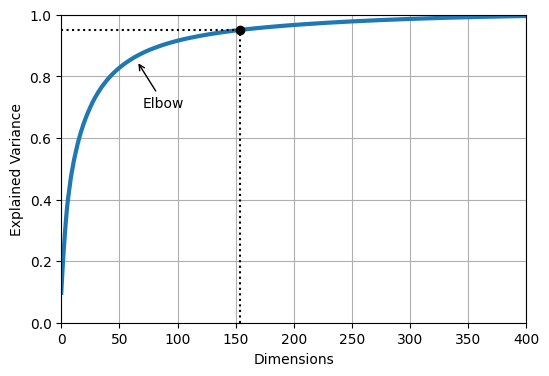

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(cumsum, linewidth=3)
plt.axis([0, 400, 0, 1])
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance")
plt.plot([d, d], [0, 0.95], "k:")
plt.plot([0, d], [0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.annotate("Elbow", xy=(65, 0.85), xytext=(70, 0.7),
             arrowprops=dict(arrowstyle="->"))
plt.grid(True)
plt.show()

→ 설명된 분산이 빠르게 늘다가 꺾이는 엘보가 있습니다. 약 100차원으로 줄여도 분산을 크게 잃지 않습니다.

지도 학습의 전처리로 쓸 때는 차원 수도 하이퍼파라미터처럼 튜닝할 수 있습니다. PCA + 랜덤 포레스트 파이프라인을 `RandomizedSearchCV`로 탐색합니다(샘플 1,000개, 10회).

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

clf = make_pipeline(PCA(random_state=42),
                    RandomForestClassifier(random_state=42))
param_distrib = {
    "pca__n_components": np.arange(10, 80),
    "randomforestclassifier__n_estimators": np.arange(50, 500)
}
rnd_search = RandomizedSearchCV(clf, param_distrib, n_iter=10, cv=3,
                                random_state=42)
rnd_search.fit(X_train[:1000], y_train[:1000])
print(rnd_search.best_params_)

{'randomforestclassifier__n_estimators': np.int64(475), 'pca__n_components': np.int64(57)}


→ 랜덤 포레스트처럼 강력한 모델에서는 784개 차원을 57개로 줄여도 충분했습니다.

선형 모델인 `SGDClassifier`로 바꾸어 PCA 차원 수만 그리드 탐색합니다.

In [18]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV

clf = make_pipeline(PCA(random_state=42), SGDClassifier(random_state=42))
param_grid = {"pca__n_components": np.arange(10, 80)}
grid_search = GridSearchCV(clf, param_grid, cv=3)
grid_search.fit(X_train[:1000], y_train[:1000])
print(grid_search.best_params_)

{'pca__n_components': np.int64(79)}


→ 선형 모델은 79개(탐색 범위의 끝)로, 랜덤 포레스트(57개)보다 더 많은 차원을 보존해야 합니다. 책에서는 약 75개이며, `SGDClassifier`는 `random_state`에 따라 결과가 조금씩 달라집니다.

### **7.3.7 압축을 위한 PCA**

MNIST에 분산 95%를 보존하는 PCA를 적용하면 특성이 784개에서 154개로 줄어 크기가 원본의 20% 미만이 됩니다. `inverse_transform()`으로 784차원으로 되돌릴 수 있지만 잃어버린 5%의 분산 때문에 원본과 완전히 같지는 않습니다.

$$\mathbf{X}_{\text{recovered}} = \mathbf{X}_{d\text{-proj}}\mathbf{W}_d^\top$$

분산 95%로 압축한 뒤 다시 784차원으로 복원합니다.

In [19]:
pca = PCA(0.95)
X_reduced = pca.fit_transform(X_train)
X_recovered = pca.inverse_transform(X_reduced)
print(X_reduced.shape, X_recovered.shape)
print("재구성 오차(MSE):", np.mean((X_train - X_recovered) ** 2))

(60000, 154) (60000, 784)


재구성 오차(MSE): 217.7936611126546


→ 154개 특성으로 압축했다가 784개로 복원했습니다. 원본과 복원본 사이의 평균 제곱 거리가 **재구성 오차**입니다.

원본 숫자와 압축 후 복원한 숫자를 나란히 그리는 함수를 만들고 비교합니다(그림 7-9).

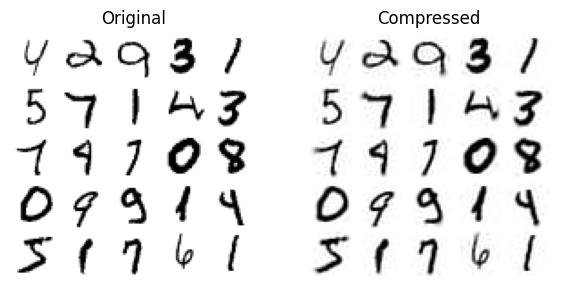

In [20]:
def plot_original_vs_compressed(X_recovered):
    # 2,100개 간격으로 고른 25개 이미지를 원본(왼쪽)과 복원본(오른쪽)으로 그림
    plt.figure(figsize=(7, 4))
    for idx, X_digits in enumerate((X_train[::2100], X_recovered[::2100])):
        plt.subplot(1, 2, idx + 1)
        plt.title(["Original", "Compressed"][idx])
        for row in range(5):
            for col in range(5):
                plt.imshow(X_digits[row * 5 + col].reshape(28, 28), cmap="binary",
                           vmin=0, vmax=255, extent=(row, row + 1, col, col + 1))
                plt.axis([0, 5, 0, 5])
                plt.axis("off")
    plt.show()


plot_original_vs_compressed(X_recovered)

→ 이미지 품질이 조금 떨어졌지만 숫자 모양은 거의 그대로입니다.

### **7.3.8 랜덤 PCA**

`svd_solver="randomized"`로 지정하면 처음 $d$개의 주성분을 확률적 알고리즘으로 빠르게 근사합니다. 계산 복잡도가 완전한 SVD의 $O(m \times n^2) + O(n^3)$ 대신 $O(m \times d^2) + O(d^3)$입니다.

랜덤 PCA로 154차원으로 줄인 뒤 **같은 `rnd_pca`** 로 복원해 비교합니다.

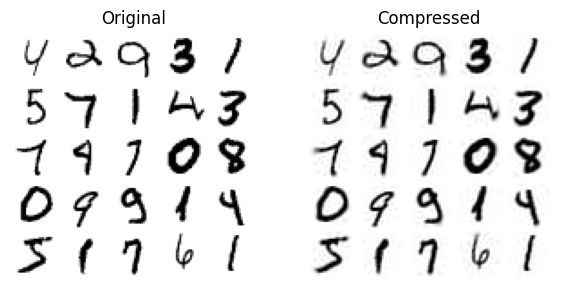

In [21]:
rnd_pca = PCA(n_components=154, svd_solver="randomized", random_state=42)
X_reduced = rnd_pca.fit_transform(X_train)
X_recovered = rnd_pca.inverse_transform(X_reduced)  # 축소에 사용한 rnd_pca로 복원
plot_original_vs_compressed(X_recovered)

→ 완전한 SVD를 사용한 결과와 거의 구별되지 않습니다.

### **7.3.9 점진적 PCA**

**점진적 PCA(IPCA, incremental PCA)** 는 훈련 세트를 미니배치로 나눠 하나씩 주입하므로 전체 데이터를 메모리에 올리지 않아도 됩니다.

`np.array_split()`으로 MNIST를 100개 미니배치로 나누고 `partial_fit()`을 반복 호출합니다.

In [22]:
from sklearn.decomposition import IncrementalPCA

n_batches = 100
inc_pca = IncrementalPCA(n_components=154)
for X_batch in np.array_split(X_train, n_batches):
    inc_pca.partial_fit(X_batch)  # fit()이 아니라 미니배치마다 partial_fit()

X_reduced = inc_pca.transform(X_train)
print(X_reduced.shape)

(60000, 154)


→ 이전과 같이 154차원으로 줄었습니다.

넘파이 `memmap`으로 디스크의 이진 파일을 메모리에 있는 배열처럼 다룹니다. 먼저 MNIST 훈련 세트를 파일에 복사하고 `flush()`로 디스크에 저장합니다.

In [23]:
filename = "my_mnist.mmap"
X_mmap = np.memmap(filename, dtype="float32", mode="write", shape=X_train.shape)
X_mmap[:] = X_train  # 실전에서는 청크 단위로 반복하며 저장
X_mmap.flush()  # 캐시에 남은 데이터를 디스크에 기록

다른 프로그램에서 하듯 memmap 파일을 다시 로드해 `IncrementalPCA`의 일반 `fit()`으로 훈련합니다.

In [24]:
# 원시 이진 데이터만 저장되므로 dtype과 크기를 지정해야 함 (생략하면 1D 배열)
X_mmap = np.memmap(filename, dtype="float32", mode="readonly").reshape(-1, 784)
batch_size = X_mmap.shape[0] // n_batches
inc_pca = IncrementalPCA(n_components=154, batch_size=batch_size)
inc_pca.fit(X_mmap);  # 세미콜론: 모델 출력 생략
print(inc_pca.batch_size, inc_pca.n_components_)

600 154


→ 배치 크기 600으로 작은 부분씩만 읽으므로 메모리 부족 없이 `fit()`을 바로 쓸 수 있습니다.

## **7.4 랜덤 투영**

랜덤한 선형 투영으로 데이터를 저차원에 투영해도 **존슨-린덴스트라우스 정리(Johnson–Lindenstrauss lemma)** 에 따라 거리가 높은 확률로 잘 보존됩니다. 보존할 최소 차원 수는 샘플 수 $m$과 허용 오차 $\varepsilon$에만 의존합니다.

$$d \ge \frac{4\log(m)}{\frac{1}{2}\varepsilon^2 - \frac{1}{3}\varepsilon^3}$$

샘플 5,000개, 허용 오차 10%일 때 필요한 최소 차원 수를 함수와 식으로 각각 계산합니다.

In [25]:
from sklearn.random_projection import johnson_lindenstrauss_min_dim

m, ε = 5_000, 0.1
d = johnson_lindenstrauss_min_dim(m, eps=ε)
print(d)
print(int(4 * np.log(m) / (ε ** 2 / 2 - ε ** 3 / 3)))  # 같은 식을 직접 계산

7300
7300


→ 두 방법 모두 7,300차원입니다. 특성 수 $n$과는 무관합니다.

평균 0, 분산 $1/d$인 가우스 분포에서 뽑은 $d \times n$ 랜덤 행렬 `P`로 20,000차원 가짜 데이터셋을 7,300차원으로 투영합니다.

In [26]:
n = 20_000
rng = np.random.default_rng(seed=42)
P = rng.standard_normal((d, n)) / np.sqrt(d)  # 표준 편차 = 분산의 제곱근

X = rng.standard_normal((m, n))  # 가짜 데이터셋 생성
X_reduced = X @ P.T
print(X_reduced.shape)

(5000, 7300)


→ (5000, 7300): 데이터는 전혀 보지 않고 크기만으로 만든 행렬 하나를 곱해 투영했습니다.

사이킷런의 `GaussianRandomProjection`으로 같은 작업을 합니다.

In [27]:
from sklearn.random_projection import GaussianRandomProjection

gaussian_rnd_proj = GaussianRandomProjection(eps=ε, random_state=42)
X_reduced = gaussian_rnd_proj.fit_transform(X)  # 앞과 같은 방식의 투영
print(gaussian_rnd_proj.components_.shape)
print(np.allclose(gaussian_rnd_proj.components_, P))  # 난수 생성기가 달라 값은 다름

(7300, 20000)


False


→ `fit()`에서 `johnson_lindenstrauss_min_dim()`으로 7,300차원을 정하고 같은 크기·분포의 랜덤 행렬을 `components_`에 저장합니다. 다만 사이킷런은 다른 난수 생성기를 쓰므로 `P`와 값이 똑같지는 않습니다(`False`).

`SparseRandomProjection`은 같은 방식으로 차원을 정하지만 랜덤 행렬이 **희소**합니다. 두 랜덤 행렬의 메모리 사용량과 밀도를 비교합니다.

In [28]:
from sklearn.random_projection import SparseRandomProjection

sparse_rnd_proj = SparseRandomProjection(eps=ε, random_state=42)
X_reduced_sparse = sparse_rnd_proj.fit_transform(X)
comp = sparse_rnd_proj.components_  # 희소 행렬 (CSR)
print("밀도:", sparse_rnd_proj.density_, "≈ 1 /", round(1 / sparse_rnd_proj.density_))
print("가우스 행렬: %.2f GB" % (gaussian_rnd_proj.components_.nbytes / 1e9))
print("희소 행렬: %.1f MB" % ((comp.data.nbytes + comp.indices.nbytes + comp.indptr.nbytes) / 1e6))

밀도: 0.007071067811865475 ≈ 1 / 141
가우스 행렬: 1.17 GB
희소 행렬: 12.5 MB


→ 기본 밀도는 $1/\sqrt{n}$이라 약 141개 항목 중 1개만 0이 아닙니다. 그래서 메모리가 1GB 이상에서 수십 MB 수준으로 크게 줄어듭니다.

⚠ 다음 셀은 몇 분 걸릴 수 있습니다. 성분 행렬의 유사역행렬(`np.linalg.pinv()`)을 구해 역변환합니다.

In [29]:
components_pinv = np.linalg.pinv(gaussian_rnd_proj.components_)  # 유사역행렬
X_recovered = X_reduced @ components_pinv.T
print(X_recovered.shape)

(5000, 20000)


→ 20,000차원으로 되돌렸습니다. `pinv()`의 계산 복잡도는 $d<n$이면 $O(dn^2)$, 아니면 $O(nd^2)$입니다.

## **7.5 지역 선형 임베딩**

**지역 선형 임베딩(LLE, locally linear embedding)** 은 투영에 의존하지 않는 **비선형 차원 축소(NLDR)** 기법입니다. 각 샘플이 최근접 이웃과 얼마나 선형적으로 연관되는지 구한 뒤, 그 국부적 관계가 가장 잘 보존되는 저차원 표현을 찾습니다.

스위스 롤을 `LocallyLinearEmbedding`(이웃 10개)으로 2D로 펼칩니다(그림 7-10).

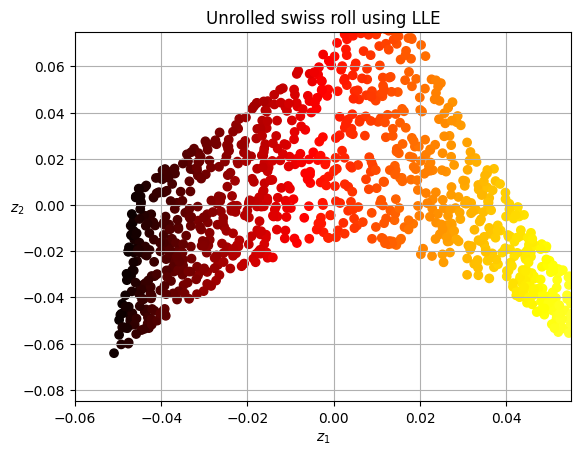

In [30]:
from sklearn.manifold import LocallyLinearEmbedding

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

plt.scatter(X_unrolled[:, 0], X_unrolled[:, 1], c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.06, 0.055, -0.085, 0.075])
plt.grid(True)
plt.title("Unrolled swiss roll using LLE")
plt.show()

→ 롤이 완전히 펼쳐졌고 지역적인 거리는 잘 보존되었습니다. 하지만 전체적으로는 직사각형이 아니라 늘어나고 꼬인 띠 모양입니다.

펼친 첫 번째 축 $z_1$과 롤 위의 위치 `t`의 관계를 그려 LLE가 매니폴드를 잘 모델링했는지 확인합니다.

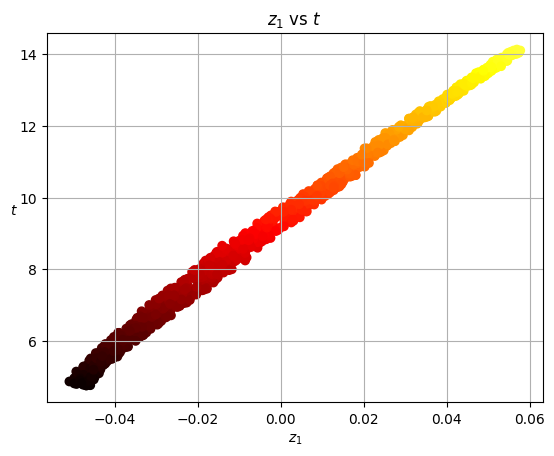

In [31]:
plt.title("$z_1$ vs $t$")
plt.scatter(X_unrolled[:, 0], t, c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$t$", rotation=0)
plt.grid(True)
plt.show()

→ $z_1$과 $t$가 거의 일대일로 대응합니다. 롤을 따라가는 위치 정보가 잘 보존되었습니다.

## **7.6 다른 차원 축소 기법**

| 기법 | 아이디어 |
|---|---|
| **MDS** (다차원 스케일링) | 샘플 간의 거리를 보존하며 축소 |
| **Isomap** | 최근접 이웃 그래프를 만들고 지오데식 거리를 보존 |
| **t-SNE** | 비슷한 샘플은 가깝게, 다른 샘플은 멀게 (주로 시각화) |
| **LDA** (선형 판별 분석) | 클래스를 가장 잘 구분하는 축으로 투영 |

스위스 롤에 MDS, Isomap, t-SNE를 적용합니다. MDS는 `n_init`의 기본값이 바뀐다는 경고가 나오므로 현재 기본값(4)을 명시합니다.

In [32]:
from sklearn.manifold import MDS, Isomap, TSNE

mds = MDS(n_components=2, n_init=4, normalized_stress=False, random_state=42)
X_reduced_mds = mds.fit_transform(X_swiss)

isomap = Isomap(n_components=2)
X_reduced_isomap = isomap.fit_transform(X_swiss)

tsne = TSNE(n_components=2, init="random", learning_rate="auto", random_state=42)
X_reduced_tsne = tsne.fit_transform(X_swiss)

세 기법의 결과를 나란히 그립니다(그림 7-11).

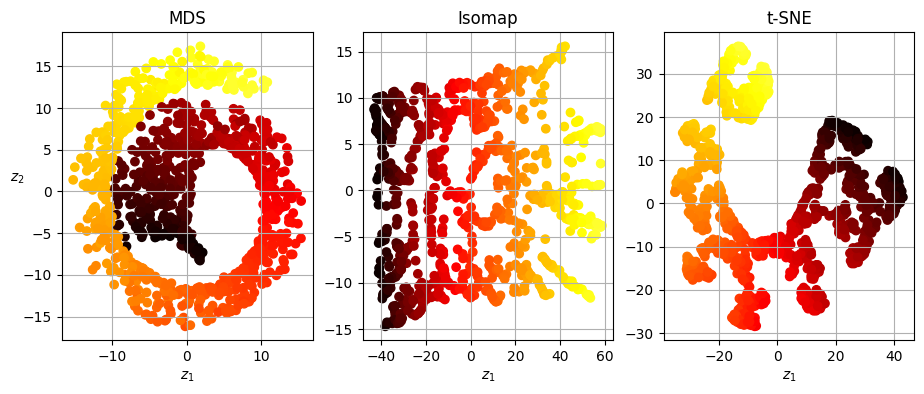

In [33]:
titles = ["MDS", "Isomap", "t-SNE"]

plt.figure(figsize=(11, 4))
for subplot, title, X_reduced in zip((131, 132, 133), titles,
                                     (X_reduced_mds, X_reduced_isomap, X_reduced_tsne)):
    plt.subplot(subplot)
    plt.title(title)
    plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=darker_hot)
    plt.xlabel("$z_1$")
    if subplot == 131:
        plt.ylabel("$z_2$", rotation=0)
    plt.grid(True)
plt.show()

→ MDS는 곡률을 유지한 채 평평하게 만들고, Isomap은 곡률을 완전히 없앱니다. t-SNE는 약간의 곡률을 남기면서 클러스터를 강조하려고 롤을 여러 조각으로 나눕니다.